<a href="https://colab.research.google.com/github/BalaMuppidathyK/AI-ML-Concepts/blob/main/Unit-2/Sentimental_Analysis_assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Installing necessary libraries**

In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn tensorflow keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [keras-tuner]


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from sklearn.metrics import classification_report

Importing the Multisentimental Analysis Dataset

In [ ]:
base_url = "https://huggingface.co/datasets/Sp1786/multiclass-sentiment-analysis-dataset/resolve/main/"

train_df = pd.read_csv(base_url + "train_df.csv")
test_df = pd.read_csv(base_url + "test_df.csv")
val_df = pd.read_csv(base_url + "val_df.csv")

print("Training Dataset:", train_df.shape)
print("Testing Dataset:", test_df.shape)
print("Validation Dataset:", val_df.shape)

train_df.head()
train_df.info()
print(train_df['sentiment'].value_counts())

Training Dataset: (31232, 4)
Testing Dataset: (5206, 4)
Validation Dataset: (5205, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31232 entries, 0 to 31231
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         31232 non-null  int64 
 1   text       31232 non-null  object
 2   label      31232 non-null  int64 
 3   sentiment  31232 non-null  object
dtypes: int64(2), object(2)
memory usage: 976.1+ KB
sentiment
neutral     11649
positive    10478
negative     9105
Name: count, dtype: int64


**Visualization of dataset**

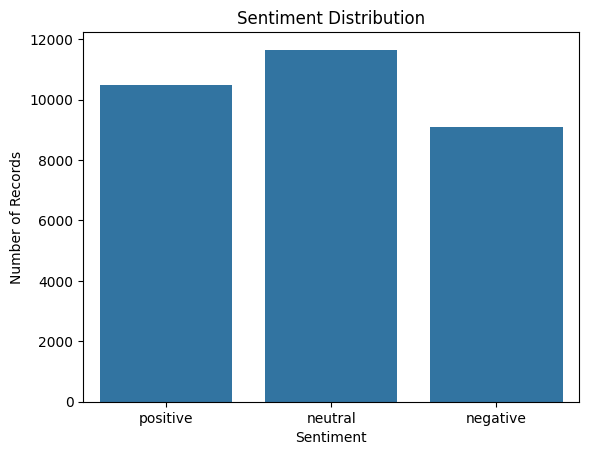

In [ ]:
sns.countplot(
    data=train_df,
    x='sentiment'
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Records")

plt.show()

**Exploratory Data Analysis**

In [ ]:
print("Training Missing Values:")
print(train_df.isnull().sum())
print("\nTesting Missing Values:")
print(test_df.isnull().sum())
print("\nValidation Missing Values:")
print(val_df.isnull().sum())

print("\nTraining Duplicates:",
      train_df['text'].duplicated().sum())
print("\nTesting Duplicates:",
      test_df['text'].duplicated().sum())
print("\nValidation Duplicates:",
      val_df['text'].duplicated().sum())

Training Missing Values:
id           0
text         0
label        0
sentiment    0
dtype: int64

Testing Missing Values:
id           0
text         1
label        0
sentiment    0
dtype: int64

Validation Missing Values:
id           0
text         0
label        0
sentiment    0
dtype: int64

Training Duplicates: 0

Testing Duplicates: 0

Validation Duplicates: 0


**Actual test text Samples**

In [ ]:
for i in range(5):
    print("Review:", train_df['text'].iloc[i])
    print("Sentiment:", train_df['sentiment'].iloc[i])
    print("Label:", train_df['label'].iloc[i])
    print("-" * 50)

Review: Cooking microwave pizzas, yummy
Sentiment: positive
Label: 2
--------------------------------------------------
Review: Any plans of allowing sub tasks to show up in the widget?
Sentiment: neutral
Label: 1
--------------------------------------------------
Review:  I love the humor, I just reworded it. Like saying 'group therapy' instead`a 'gang banging'. Keeps my moms off my back.   Hahaha
Sentiment: positive
Label: 2
--------------------------------------------------
Review:  naw idk what ur talkin about
Sentiment: neutral
Label: 1
--------------------------------------------------
Review:  That sucks to hear. I hate days like that
Sentiment: negative
Label: 0
--------------------------------------------------


**Verification of Labels mapped with their sentiment names**

In [ ]:
#labels mapped with their sentiment names
print(
    train_df[['label', 'sentiment']]
    .drop_duplicates()
    .sort_values('label')
)

   label sentiment
4      0  negative
1      1   neutral
0      2  positive


In [ ]:
test_df[test_df['text'].isnull()]
test_eval_df = test_df.dropna(subset=['text']).copy()
print(test_eval_df.shape)

(5205, 4)


In [ ]:
train_texts = set(train_df['text'].dropna())
test_texts = set(test_eval_df['text'].dropna())
val_texts = set(val_df['text'].dropna())

#Checking overlap between train,test and validate split
print("Train-Test Overlap:",
      len(train_texts & test_texts))
print("Train-Validation Overlap:",
      len(train_texts & val_texts))
print("Validation-Test Overlap:",
      len(val_texts & test_texts))

Train-Test Overlap: 0
Train-Validation Overlap: 0
Validation-Test Overlap: 0


**Text Preprocessing**

In [ ]:
# Remove the one missing text record from testing data
test_eval_df = test_df.dropna(subset=['text']).copy()

# Input features
X_train = train_df['text'].astype(str)
X_val = val_df['text'].astype(str)
X_test = test_eval_df['text'].astype(str)

# Target labels
y_train = train_df['label'].astype('int32')
y_val = val_df['label'].astype('int32')
y_test = test_eval_df['label'].astype('int32')

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 31232
Validation samples: 5205
Testing samples: 5205


**Tokenization**

In [ ]:
import tensorflow as tf
import numpy as np

MAX_TOKENS = 20000
MAX_LEN = 96

vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    standardize="lower_and_strip_punctuation",
    split="whitespace",
    output_mode="int",
    output_sequence_length=MAX_LEN
)

# Learn vocabulary using training data only
vectorizer.adapt(X_train)

# Learn vocabulary only from training text, here only determining the size for
# X_train as model learns from the training set only
vectorizer.adapt(X_train)

#Vocabulory Size
vocabulary = vectorizer.get_vocabulary()
print("Vocabulary size:", len(vocabulary))
print("First 20 words:",vocabulary[:20])

Vocabulary size: 20000
First 20 words: ['', '[UNK]', np.str_('i'), np.str_('the'), np.str_('to'), np.str_('a'), np.str_('and'), np.str_('it'), np.str_('my'), np.str_('is'), np.str_('for'), np.str_('you'), np.str_('of'), np.str_('app'), np.str_('in'), np.str_('but'), np.str_('this'), np.str_('that'), np.str_('have'), np.str_('on')]


**Encoding**

In [ ]:
sample_text = X_train.iloc[0]

print("Original Text:")
print(sample_text)

encoded_text = vectorizer(tf.constant([sample_text]))

print("\nNumerical Representation:")
print(encoded_text.numpy().tolist())

Original Text:
Cooking microwave pizzas, yummy

Numerical Representation:
[[2697, 10124, 6043, 1273, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]



Minimum length: 0
Maximum length: 96
Average length: 17.71
Median length: 13.0
90th percentile: 33.0
95th percentile: 56.0
99th percentile: 91.0


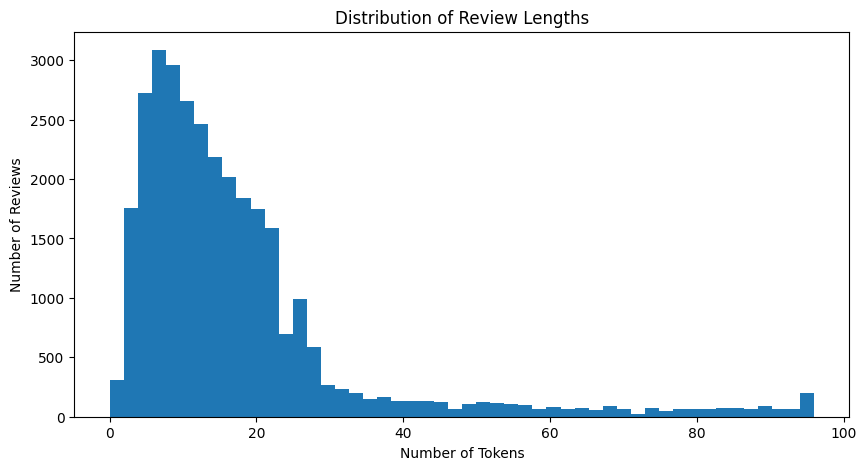

In [ ]:
# Convert each review into a variable-length sequence
encoded_train = vectorizer(
    tf.constant(X_train.tolist())
)

# Count non-padding (non-zero) tokens in each review
sequence_lengths = tf.math.count_nonzero(encoded_train, axis=1).numpy()

print("\nMinimum length:", sequence_lengths.min())
print("Maximum length:", sequence_lengths.max())

print("Average length:", round(sequence_lengths.mean(), 2))

print("Median length:", np.median(sequence_lengths))

print("90th percentile:", np.percentile(sequence_lengths, 90))

print("95th percentile:", np.percentile(sequence_lengths, 95))

print("99th percentile:", np.percentile(sequence_lengths, 99))

#Visualization of Sequence Length
plt.figure(figsize=(10, 5))

plt.hist(sequence_lengths, bins=50)

plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Tokens")
plt.ylabel("Number of Reviews")

plt.show()

**Creating Embedding layer**

In [ ]:
#Numerical representation to Word Embeddings
tf.keras.layers.Embedding(
    input_dim=20000,
    output_dim=64,
    mask_zero=True
)

<Embedding name=embedding, built=False>

**Comparison of Sequence length**

In [ ]:
length_options = [56, 64, 96, 128]

for max_len in length_options:

    truncated = np.sum(sequence_lengths > max_len)

    percentage = (truncated / len(sequence_lengths)) * 100

    print(f"\nMAX_LEN: {max_len}")
    print("Reviews truncated:", truncated)
    print("Truncation percentage:", round(percentage, 2), "%")

for max_len in length_options:

    removed_tokens = np.maximum(
        sequence_lengths - max_len, 0
    ).sum()

    print(
        f"\nMAX_LEN {max_len}: "
        f"{removed_tokens} tokens removed"
    )


MAX_LEN: 56
Reviews truncated: 1532
Truncation percentage: 4.91 %

MAX_LEN: 64
Reviews truncated: 1225
Truncation percentage: 3.92 %

MAX_LEN: 96
Reviews truncated: 0
Truncation percentage: 0.0 %

MAX_LEN: 128
Reviews truncated: 0
Truncation percentage: 0.0 %

MAX_LEN 56: 33504 tokens removed

MAX_LEN 64: 22404 tokens removed

MAX_LEN 96: 0 tokens removed

MAX_LEN 128: 0 tokens removed


In [ ]:
# Find reviews that became empty after tokenization

zero_length_indices = np.where(sequence_lengths == 0)[0]

print("Number of empty reviews:", len(zero_length_indices))
print("\nEmpty review samples:")

for i in zero_length_indices[:10]:
    print(repr(X_train.iloc[i]))

# Identify non-empty reviews using the existing sequence lengths
non_empty_mask = sequence_lengths > 0

# Keep only valid training reviews
X_train = X_train.iloc[non_empty_mask].reset_index(drop=True)
y_train = y_train.iloc[non_empty_mask].reset_index(drop=True)

print("Updated training samples:", len(X_train))
print("Empty reviews remaining:", np.sum(~non_empty_mask))

Number of empty reviews: 1

Empty review samples:
' ****'
Updated training samples: 31231
Empty reviews remaining: 1


**VERIFICATION OF CHANGES IN TEXT PREPROCESSING**

In [ ]:
#6.2
X_train_seq = vectorizer(
    tf.constant(X_train.tolist())
)

X_val_seq = vectorizer(
    tf.constant(X_val.tolist())
)

X_test_seq = vectorizer(
    tf.constant(X_test.tolist())
)

print("Training shape:", X_train_seq.shape)
print("Validation shape:", X_val_seq.shape)
print("Testing shape:", X_test_seq.shape)

#6.3
print("\nOriginal review:")
print(X_train.iloc[3])

print("\nNumerical representation:")
print(X_train_seq[3].numpy())

#6.4
print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)

Training shape: (31231, 96)
Validation shape: (5205, 96)
Testing shape: (5205, 96)

Original review:
 naw idk what ur talkin about

Numerical representation:
[4638 1124   58  334 3242   81    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0]
Training labels: (31231,)
Validation labels: (5205,)
Testing labels: (5205,)


**Artificial Neural Network**

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [ ]:
VOCAB_SIZE = len(vectorizer.get_vocabulary())

EMBEDDING_DIM = 64
MAX_LEN = 96
NUM_CLASSES = 3

ann_model = models.Sequential([

    layers.Input(shape=(MAX_LEN,)),

    layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True),

    layers.GlobalAveragePooling1D(),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.4),

    layers.Dense(NUM_CLASSES, activation='softmax')

])

In [ ]:
ann_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
ann_model.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_13 (Embedding)        │ (None, 96, 64)         │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_13     │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,296,771 (4.95 MB)

 Trainable params: 1,296,771 (4.95 MB)

 Non-trainable params: 0 (0.00 B)

**Training the model**

In [ ]:
history_ann = ann_model.fit(X_train_seq, y_train,  validation_data=(X_val_seq, y_val), epochs=3, batch_size=64, verbose=1)
print("Model Trained Successfully")

Epoch 1/3
488/488 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5922 - loss: 0.8541 - val_accuracy: 0.6581 - val_loss: 0.7610
Epoch 2/3
488/488 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7329 - loss: 0.6439 - val_accuracy: 0.6560 - val_loss: 0.7666
Epoch 3/3
488/488 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7980 - loss: 0.5223 - val_accuracy: 0.6518 - val_loss: 0.8391
Model Trained Successfully


**Training Performance**

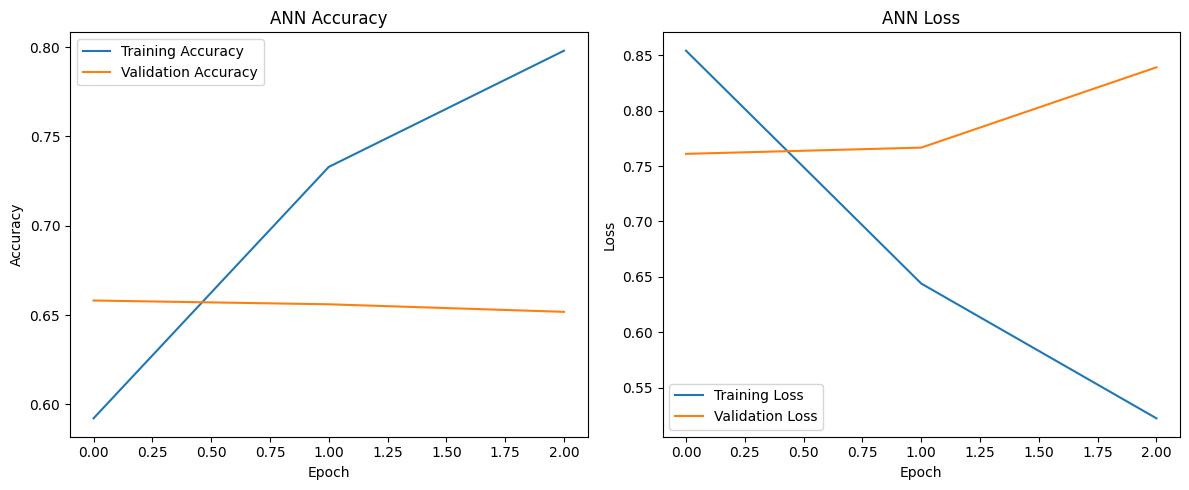

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history_ann.history['accuracy'],
         label='Training Accuracy')

plt.plot(history_ann.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('ANN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(history_ann.history['loss'],
         label='Training Loss')

plt.plot(history_ann.history['val_loss'],
         label='Validation Loss')

plt.title('ANN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

**Testing the model**

In [ ]:
test_loss, test_accuracy = ann_model.evaluate(X_test_seq,y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

163/163 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6519 - loss: 0.8526
Test Loss: 0.8525536060333252
Test Accuracy: 0.6518731713294983


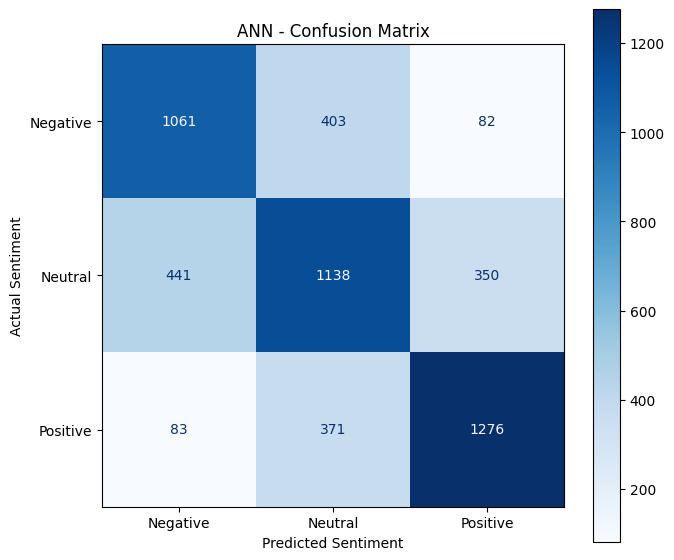

Confusion Matrix:
[[1061  403   82]
 [ 441 1138  350]
 [  83  371 1276]]
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
              precision    recall  f1-score   support

    Negative       0.65      0.67      0.66      1546
     Neutral       0.59      0.57      0.58      1929
    Positive       0.72      0.73      0.72      1730

    accuracy                           0.65      5205
   macro avg       0.65      0.66      0.65      5205
weighted avg       0.65      0.65      0.65      5205



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict sentiment for test data
y_pred_prob = best_ann_model.predict(X_test_seq, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

# Actual labels
y_true = np.asarray(y_test)

# Generate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

# Display confusion matrix
class_names = ["Negative", "Neutral", "Positive"]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("ANN - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)

y_pred_prob = ann_model.predict(X_test_seq)
y_pred = np.argmax(y_pred_prob, axis=1)

print(classification_report(y_test, y_pred,target_names=['Negative','Neutral','Positive']))

**RNN**

In [ ]:
def build_rnn_model(
    rnn_units=64,
    dropout_rate=0.4,
    learning_rate=0.001
):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(MAX_LEN,)),
        tf.keras.layers.Embedding(input_dim=VOCAB_SIZE,output_dim=64,mask_zero=True),
        tf.keras.layers.SimpleRNN(rnn_units),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(9,activation="relu"),
        tf.keras.layers.Dropout(0.4),
        tf.keras.layers.Dense(3,activation="softmax")])

    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)

    model.compile(optimizer=optimizer,loss="sparse_categorical_crossentropy",metrics=["accuracy"])

    return model

In [ ]:
tf.keras.utils.set_random_seed(42)

rnn_model = build_rnn_model()

early_stopping = tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True)

rnn_history = rnn_model.fit(X_train_seq,y_train_np,validation_data=(X_val_seq, y_val_np),epochs=4,batch_size=64,callbacks=[early_stopping],verbose=1)
rnn_results = rnn_model.evaluate(X_val_seq,y_val_np,return_dict=True,verbose=0)

print("RNN Validation Results:", rnn_results)

Epoch 1/4
488/488 ━━━━━━━━━━━━━━━━━━━━ 16s 20ms/step - accuracy: 0.4694 - loss: 1.0101 - val_accuracy: 0.6070 - val_loss: 0.8763
Epoch 2/4
488/488 ━━━━━━━━━━━━━━━━━━━━ 14s 11ms/step - accuracy: 0.6354 - loss: 0.8168 - val_accuracy: 0.6307 - val_loss: 0.8167
Epoch 3/4
488/488 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.7065 - loss: 0.7012 - val_accuracy: 0.6036 - val_loss: 0.9279
Epoch 4/4
488/488 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.7616 - loss: 0.5897 - val_accuracy: 0.6184 - val_loss: 0.9409
RNN Validation Results: {'accuracy': 0.6306686997413635, 'loss': 0.8166818022727966}


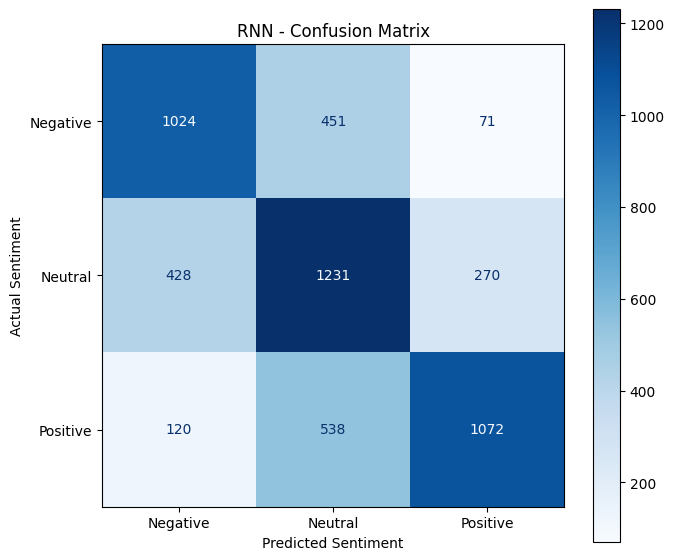

RNN Classification Report:
              precision    recall  f1-score   support

    Negative       0.65      0.66      0.66      1546
     Neutral       0.55      0.64      0.59      1929
    Positive       0.76      0.62      0.68      1730

    accuracy                           0.64      5205
   macro avg       0.65      0.64      0.64      5205
weighted avg       0.65      0.64      0.64      5205

RNN Confusion Matrix:
[[1024  451   71]
 [ 428 1231  270]
 [ 120  538 1072]]


In [ ]:
# 1. Predict using RNN model
rnn_y_pred_prob = rnn_model.predict(X_test_seq, verbose=0)

# 2. Convert probabilities into class labels
rnn_y_pred = np.argmax(rnn_y_pred_prob, axis=1)

# 3. Actual test labels
rnn_y_true = np.asarray(y_test)

# 4. Generate confusion matrix
class_names = ["Negative", "Neutral", "Positive"]

rnn_cm = confusion_matrix(
    rnn_y_true,
    rnn_y_pred,
    labels=[0, 1, 2]
)

# 5. Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=rnn_cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("RNN - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 6. Classification report
print("RNN Classification Report:")
print(classification_report(
    rnn_y_true,
    rnn_y_pred,
    target_names=class_names
))

print("RNN Confusion Matrix:")
print(rnn_cm)

**LSTM**

In [ ]:
def build_lstm_model(
    lstm_units=64,
    dropout_rate=0.3,
    learning_rate=0.001
):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(MAX_LEN,)),
        tf.keras.layers.Embedding(input_dim=VOCAB_SIZE,output_dim=64,mask_zero=True),
        tf.keras.layers.LSTM(lstm_units),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(24,activation="relu"),
        tf.keras.layers.Dense(15,activation="relu"),
        tf.keras.layers.Dropout(0.4),
        tf.keras.layers.Dense(3,activation="softmax")
    ])

    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)

    model.compile(optimizer=optimizer,loss="sparse_categorical_crossentropy",metrics=["accuracy"])

    return model


In [ ]:
tf.keras.utils.set_random_seed(54)

lstm_model = build_lstm_model()

early_stopping = tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True)

lstm_history = lstm_model.fit(X_train_seq,y_train_np,validation_data=(X_val_seq, y_val_np),epochs=3,batch_size=64,callbacks=[early_stopping],verbose=1)


lstm_results = lstm_model.evaluate(X_val_seq,y_val_np,return_dict=True,verbose=0)

print("LSTM Validation Results:", lstm_results)


Epoch 1/3
488/488 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.5599 - loss: 0.9225 - val_accuracy: 0.6526 - val_loss: 0.7886
Epoch 2/3
488/488 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.7134 - loss: 0.6993 - val_accuracy: 0.6728 - val_loss: 0.7484
Epoch 3/3
488/488 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.7732 - loss: 0.5794 - val_accuracy: 0.6697 - val_loss: 0.8495
LSTM Validation Results: {'accuracy': 0.6727517247200012, 'loss': 0.7483905553817749}


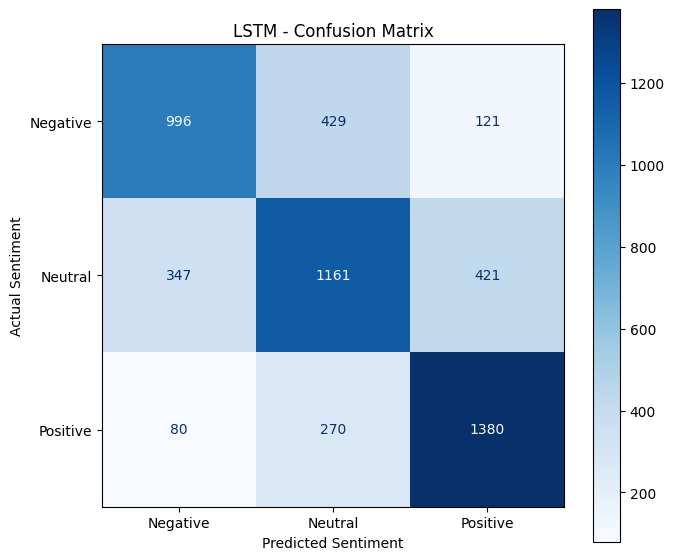

LSTM Classification Report:
              precision    recall  f1-score   support

    Negative       0.70      0.64      0.67      1546
     Neutral       0.62      0.60      0.61      1929
    Positive       0.72      0.80      0.76      1730

    accuracy                           0.68      5205
   macro avg       0.68      0.68      0.68      5205
weighted avg       0.68      0.68      0.68      5205

LSTM Confusion Matrix:
[[ 996  429  121]
 [ 347 1161  421]
 [  80  270 1380]]


In [ ]:
lstm_y_pred_prob = lstm_model.predict(X_test_seq, verbose=0)
lstm_y_pred = np.argmax(lstm_y_pred_prob, axis=1)
lstm_y_true = np.asarray(y_test)

# Confusion matrix
class_names = ["Negative", "Neutral", "Positive"]

lstm_cm = confusion_matrix(lstm_y_true,lstm_y_pred,labels=[0, 1, 2])

disp = ConfusionMatrixDisplay(confusion_matrix=lstm_cm,display_labels=class_names)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("LSTM - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()
plt.show()

# Classification report
print("LSTM Classification Report:")
print(classification_report(
    lstm_y_true,
    lstm_y_pred,
    target_names=class_names
))

print("LSTM Confusion Matrix:")
print(lstm_cm)


**GRU**

In [ ]:

def build_gru_model(
    gru_units=64,
    dropout_rate=0.4,
    learning_rate=0.001
):

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(MAX_LEN,)),

        tf.keras.layers.Embedding(input_dim=VOCAB_SIZE,output_dim=64,mask_zero=True),

        tf.keras.layers.GRU(gru_units),

        tf.keras.layers.Dense(24,activation="relu"),
        tf.keras.layers.Dense(15,activation="relu"),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(3,activation="softmax")
    ])

    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer,loss="sparse_categorical_crossentropy",metrics=["accuracy"])
    return model


In [ ]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(54)

gru_model = build_gru_model()

early_stopping = tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True)

gru_history = gru_model.fit(X_train_seq,y_train_np,validation_data=(X_val_seq, y_val_np),epochs=10,batch_size=64,callbacks=[early_stopping],verbose=1)


gru_results = gru_model.evaluate(X_val_seq,y_val_np,return_dict=True,verbose=0)

print("GRU Validation Results:", gru_results)

Epoch 1/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.5648 - loss: 0.9074 - val_accuracy: 0.6443 - val_loss: 0.7955
Epoch 2/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.7110 - loss: 0.7161 - val_accuracy: 0.6674 - val_loss: 0.7781
Epoch 3/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.7741 - loss: 0.5884 - val_accuracy: 0.6507 - val_loss: 0.8631
Epoch 4/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8132 - loss: 0.4951 - val_accuracy: 0.6457 - val_loss: 0.9292
Epoch 5/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.8430 - loss: 0.4132 - val_accuracy: 0.6545 - val_loss: 1.0498
GRU Validation Results: {'accuracy': 0.6673712730407715, 'loss': 0.7780886292457581}


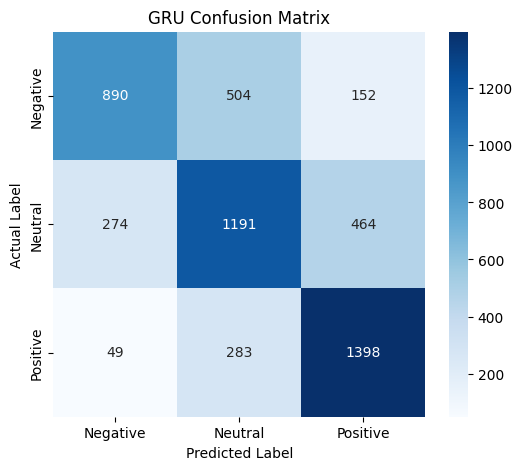

GRU Classification Report:
              precision    recall  f1-score   support

    Negative       0.73      0.58      0.65      1546
     Neutral       0.60      0.62      0.61      1929
    Positive       0.69      0.81      0.75      1730

    accuracy                           0.67      5205
   macro avg       0.68      0.67      0.67      5205
weighted avg       0.67      0.67      0.67      5205

GRU Confusion Matrix:
[[ 890  504  152]
 [ 274 1191  464]
 [  49  283 1398]]


In [ ]:
# Predict probabilities
gru_y_pred_prob = gru_model.predict(X_test_seq, verbose=0)

# Convert probabilities into class predictions
gru_y_pred = np.argmax(gru_y_pred_prob, axis=1)

# Actual labels
gru_y_true = np.asarray(y_test)

# Confusion Matrix
gru_cm = confusion_matrix(gru_y_true,gru_y_pred,labels=[0, 1, 2])

plt.figure(figsize=(6, 5))
sns.heatmap(
    gru_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("GRU Confusion Matrix")
plt.show()

# Classification Report
print("GRU Classification Report:")
print(
    classification_report(
        gru_y_true,
        gru_y_pred,
        target_names=["Negative", "Neutral", "Positive"]
    )
)
print("GRU Confusion Matrix:")
print(gru_cm)

**Autotuning of Hyperparameters**

In [ ]:
%pip install -q keras-tuner

import tensorflow as tf
import keras_tuner as kt
import numpy as np
import pandas as pd

from tensorflow.keras import layers
from tensorflow.keras import models
from tensorflow.keras.callbacks import EarlyStopping

MAX_LEN = 96
VOCAB_SIZE = len(vectorizer.get_vocabulary())
NUM_CLASSES = 3

print("Vocabulary Size:", VOCAB_SIZE)
print("Training Shape:", X_train_seq.shape)
print("Validation Shape:", X_val_seq.shape)
print("Testing Shape:", X_test_seq.shape)

Vocabulary Size: 20000
Training Shape: (31231, 96)
Validation Shape: (5204, 96)
Testing Shape: (5205, 96)


**Hypermodel Class**

In [ ]:
class SentimentHyperModel(kt.HyperModel):

    def __init__(self, architecture):
        self.architecture = architecture

    def build(self, hp):

        # Tune embedding dimension
        embedding_dim = hp.Choice("embedding_dim",values=[32, 64, 100])

        # Tune dense layer neurons
        dense_1 = hp.Choice("dense_1",values=[32, 64, 128])
        dense_2 = hp.Choice("dense_2",values=[16, 32, 64])

        # Tune dropout
        dropout_rate = hp.Choice("dropout_rate",values=[0.2, 0.3, 0.4, 0.5])

        # Tune learning rate
        learning_rate = hp.Choice("learning_rate",values=[0.001, 0.0005, 0.0001])

        model = models.Sequential()

        model.add(layers.Input(shape=(MAX_LEN,)))

        model.add(
            layers.Embedding(input_dim=VOCAB_SIZE,output_dim=embedding_dim,mask_zero=True))

        # Select architecture
        if self.architecture == "ANN":
            model.add(layers.GlobalAveragePooling1D())

        elif self.architecture == "RNN":

            recurrent_units = hp.Choice("recurrent_units",values=[32, 64, 128])

            model.add(layers.SimpleRNN(recurrent_units))

        elif self.architecture == "LSTM":

            recurrent_units = hp.Choice("recurrent_units",values=[32, 64, 128])

            model.add(layers.LSTM(recurrent_units))

        elif self.architecture == "GRU":

            recurrent_units = hp.Choice("recurrent_units",values=[32, 64, 128])

            model.add(layers.GRU(recurrent_units))

        # Common dense layers
        model.add(layers.Dense(dense_1, activation="relu"))

        model.add(layers.Dropout(dropout_rate))

        model.add(layers.Dense(dense_2, activation="relu"))

        # Output layer: 3 sentiment classes
        model.add(layers.Dense(NUM_CLASSES, activation="softmax"))

        # Optimizer
        optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)

        model.compile(optimizer=optimizer,loss="sparse_categorical_crossentropy",metrics=["accuracy"])

        return model

    # Tune batch size during training
    def fit(self, hp, model, x, y, validation_data=None,callbacks=None, **kwargs):

        batch_size = hp.Choice("batch_size",values=[32, 64, 128])

        return model.fit(x,y,validation_data=validation_data,batch_size=batch_size,callbacks=callbacks,**kwargs)

**Automatic Tuning function**

In [ ]:
def tune_model(architecture):

    print("\n" + "=" * 60)
    print("STARTING HYPERPARAMETER TUNING:", architecture)
    print("=" * 60)

    tf.keras.backend.clear_session()

    # Create HyperModel
    hypermodel = SentimentHyperModel(architecture)

    # Random Search tuner
    tuner = kt.RandomSearch(hypermodel=hypermodel,objective="val_accuracy",max_trials=10,executions_per_trial=1,directory="sentiment_tuning",project_name=architecture,overwrite=True,seed=54)

    # Early stopping
    early_stopping = EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True)

    # Start automatic search
    tuner.search(X_train_seq,y_train_np,validation_data=(X_val_seq, y_val_np),epochs=15,callbacks=[early_stopping],verbose=1)

    # Get best hyperparameters
    best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

    # Get best model
    best_model = tuner.get_best_models(num_models=1)[0]

    # Display results
    print("\nBest Hyperparameters for", architecture)
    print(best_hp.values)

    # Evaluate on validation data
    val_results = best_model.evaluate(X_val_seq,y_val_np,return_dict=True,verbose=0)

    print("\nBest Validation Results:")
    print(val_results)

    return tuner, best_model, best_hp, val_results

In [ ]:
architectures = ["ANN", "RNN", "LSTM", "GRU"]

tuning_results = {}
best_models = {}
best_hyperparameters = {}
validation_results = {}

for architecture in architectures:

    tuner, model, hp, val_result = tune_model(architecture)

    tuning_results[architecture] = tuner
    best_models[architecture] = model
    best_hyperparameters[architecture] = hp
    validation_results[architecture] = val_result

Trial 10 Complete [00h 00m 35s]
val_accuracy: 0.6612221598625183

Best val_accuracy So Far: 0.6902382969856262
Total elapsed time: 00h 07m 27s

Best Hyperparameters for GRU
{'embedding_dim': 64, 'dense_1': 32, 'dense_2': 32, 'dropout_rate': 0.4, 'learning_rate': 0.001, 'recurrent_units': 128, 'batch_size': 32}

Best Validation Results:
{'accuracy': 0.6902382969856262, 'loss': 0.7297889590263367}


In [ ]:
comparison_data = []

for architecture in architectures:

    hp = best_hyperparameters[architecture]
    result = validation_results[architecture]

    comparison_data.append({
        "Model": architecture,
        "Best Validation Accuracy": result["accuracy"],
        "Best Validation Loss": result["loss"],
        "Embedding Dimension": hp.get("embedding_dim"),
        "Recurrent Units": hp.values.get("recurrent_units", "N/A"),
        "Dense Layer 1": hp.get("dense_1"),
        "Dense Layer 2": hp.get("dense_2"),
        "Dropout": hp.get("dropout_rate"),
        "Learning Rate": hp.get("learning_rate"),
        "Batch Size": hp.get("batch_size")
    })

tuning_comparison = pd.DataFrame(comparison_data)

print(tuning_comparison.to_string(index=False))

Model  Best Validation Accuracy  Best Validation Loss  Embedding Dimension Recurrent Units  Dense Layer 1  Dense Layer 2  Dropout  Learning Rate  Batch Size
  ANN                  0.669869              0.754364                   32             N/A             32             16      0.5         0.0001          64
  RNN                  0.657763              0.847567                   32              32            128             64      0.5         0.0001          32
 LSTM                  0.675826              0.914016                   64             128             32             32      0.4         0.0010          32
  GRU                  0.690238              0.729789                   64             128             32             32      0.4         0.0010          32


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

y_test_array = np.asarray(y_test)

final_test_results = []

for architecture in architectures:

    print("\n", "=" * 50)
    print("FINAL TEST RESULTS:", architecture)
    print("=" * 50)

    model = best_models[architecture]

    # Evaluate test accuracy and loss
    test_result = model.evaluate(X_test_seq,y_test_array,return_dict=True,verbose=0)

    # Predictions
    predictions = model.predict(X_test_seq,verbose=0)

    y_pred = np.argmax(predictions, axis=1)

    print("\nTest Results:", test_result)

    print("\nClassification Report:")
    print(classification_report(y_test_array,y_pred,target_names=["Negative", "Neutral", "Positive"]))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test_array,y_pred,labels=[0, 1, 2]))

    final_test_results.append({"Model": architecture,"Test Accuracy": test_result["accuracy"],"Test Loss": test_result["loss"]})

final_comparison = pd.DataFrame(final_test_results)

print("\nFINAL MODEL COMPARISON")
print(final_comparison.to_string(index=False))


FINAL TEST RESULTS: ANN

Test Results: {'accuracy': 0.6731988191604614, 'loss': 0.7629627585411072}

Classification Report:
              precision    recall  f1-score   support

    Negative       0.72      0.61      0.66      1546
     Neutral       0.59      0.65      0.62      1929
    Positive       0.75      0.75      0.75      1730

    accuracy                           0.67      5205
   macro avg       0.68      0.67      0.68      5205
weighted avg       0.68      0.67      0.67      5205


Confusion Matrix:
[[ 947  513   86]
 [ 316 1259  354]
 [  56  376 1298]]

FINAL TEST RESULTS: RNN

Test Results: {'accuracy': 0.649759829044342, 'loss': 0.8536072969436646}

Classification Report:
              precision    recall  f1-score   support

    Negative       0.71      0.55      0.62      1546
     Neutral       0.57      0.62      0.59      1929
    Positive       0.70      0.77      0.73      1730

    accuracy                           0.65      5205
   macro avg       0.66 

In [ ]:
for architecture in architectures:

    print("\n", "=" * 50)
    print("BEST HYPERPARAMETERS:", architecture)
    print("=" * 50)

    print(best_hyperparameters[architecture].values)

    print("\nValidation Results:")
    print(validation_results[architecture])
print(tuning_comparison.to_string(index=False))


BEST HYPERPARAMETERS: ANN
{'embedding_dim': 32, 'dense_1': 32, 'dense_2': 16, 'dropout_rate': 0.5, 'learning_rate': 0.0001, 'batch_size': 64}

Validation Results:
{'accuracy': 0.6698693037033081, 'loss': 0.7543644309043884}

BEST HYPERPARAMETERS: RNN
{'embedding_dim': 32, 'dense_1': 128, 'dense_2': 64, 'dropout_rate': 0.5, 'learning_rate': 0.0001, 'recurrent_units': 32, 'batch_size': 32}

Validation Results:
{'accuracy': 0.6577632427215576, 'loss': 0.8475671410560608}

BEST HYPERPARAMETERS: LSTM
{'embedding_dim': 64, 'dense_1': 32, 'dense_2': 32, 'dropout_rate': 0.4, 'learning_rate': 0.001, 'recurrent_units': 128, 'batch_size': 32}

Validation Results:
{'accuracy': 0.6758263111114502, 'loss': 0.9140155911445618}

BEST HYPERPARAMETERS: GRU
{'embedding_dim': 64, 'dense_1': 32, 'dense_2': 32, 'dropout_rate': 0.4, 'learning_rate': 0.001, 'recurrent_units': 128, 'batch_size': 32}

Validation Results:
{'accuracy': 0.6902382969856262, 'loss': 0.7297889590263367}
Model  Best Validation Accura

**Best Model**

In [ ]:
best_gru_model = best_models["GRU"]

best_gru_model.save("best_gru_sentiment_model.keras")

print("Best GRU model saved successfully!")

import json

gru_hp = best_hyperparameters["GRU"].values

with open("best_gru_hyperparameters.json", "w") as file:
    json.dump(gru_hp, file, indent=4)

print("GRU hyperparameters saved successfully!")

Best GRU model saved successfully!
GRU hyperparameters saved successfully!


In [ ]:
# Load saved GRU model
loaded_model = tf.keras.models.load_model(
    "best_gru_sentiment_model.keras"
)

# Sample sentences
sample_reviews = [
    "This product is absolutely amazing and I love it",
    "The experience was terrible and very disappointing",
    "The product is okay, nothing special"
]

# Convert text into sequences using the same fitted vectorizer
sample_sequences = vectorizer(
    tf.constant(sample_reviews)
)

# Predict sentiment
predictions = loaded_model.predict(sample_sequences)

# Class names
sentiment_labels = ["Negative", "Neutral", "Positive"]

for review, prediction in zip(sample_reviews, predictions):

    predicted_class = np.argmax(prediction)
    confidence = np.max(prediction) * 100

    print("\nReview:", review)
    print("Predicted Sentiment:", sentiment_labels[predicted_class])
    print("Confidence:", round(confidence, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 22 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step

Review: This product is absolutely amazing and I love it
Predicted Sentiment: Positive
Confidence: 99.02 %

Review: The experience was terrible and very disappointing
Predicted Sentiment: Negative
Confidence: 99.73 %

Review: The product is okay, nothing special
Predicted Sentiment: Neutral
Confidence: 48.39 %


**Confusion matrix of All four models**

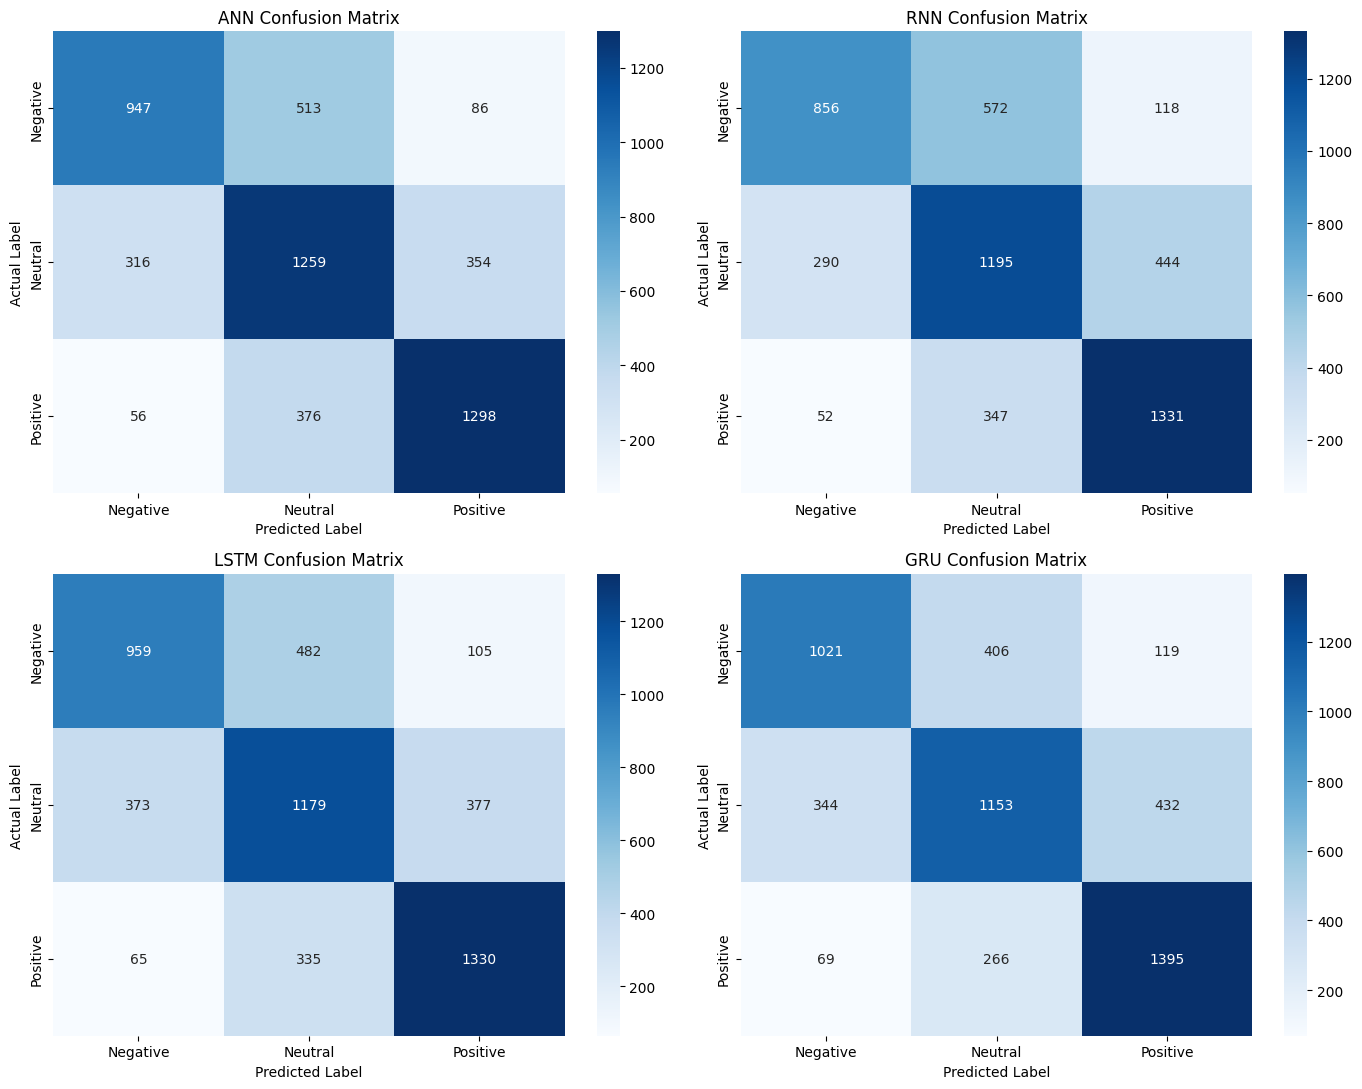

<Figure size 640x480 with 0 Axes>

In [ ]:
# Actual test labels
y_true = np.asarray(y_test)

# Model names
architectures = ["ANN", "RNN", "LSTM", "GRU"]

# Create 2x2 subplot
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

axes = axes.flatten()

class_names = ["Negative", "Neutral", "Positive"]

# Generate confusion matrix for each model
for i, architecture in enumerate(architectures):

    # Get best tuned model
    model = best_models[architecture]

    # Predict test data
    y_pred_prob = model.predict(X_test_seq, verbose=0)

    # Convert probabilities into class labels
    y_pred = np.argmax(y_pred_prob, axis=1)

    # Generate confusion matrix
    cm = confusion_matrix(y_true,y_pred,labels=[0, 1, 2])

    # Plot confusion matrix
    sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=class_names,yticklabels=class_names,ax=axes[i])

    axes[i].set_title(f"{architecture} Confusion Matrix")
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()
plt.savefig("All_Models_Confusion_Matrices.png",dpi=300,bbox_inches="tight")